# DSCI 552 - Homework 5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

## 1. Decision Trees as Interpretable Models

### (a) Load the data

In [2]:
q1_cols = ['Temperature', 'Nausea', 'Lumbar_Pain', 'Urine_Pushing',
           'Micturition_Pains', 'Burning_Urethra', 'Inflammation', 'Nephritis']

# the file is utf-16 encoded and uses a decimal comma for temperature
diag = pd.read_csv('diagnosis.data', sep=r'\s+', header=None,
                   names=q1_cols, encoding='utf-16')
diag['Temperature'] = diag['Temperature'].str.replace(',', '.').astype(float)
for c in q1_cols[1:]:
    diag[c] = diag[c].map({'no': 0, 'yes': 1})

print(diag.shape)
diag.head()

(120, 8)


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Decision tree on the whole data set

There are two labels (Inflammation of urinary bladder, Nephritis of renal pelvis origin). I used the **label powerset** method:
the pair of labels is turned into one class, so there are 4 classes (no/no, no/yes, yes/no, yes/yes).

I think label powerset is the better choice here. There are only 4 possible label combinations and all of them appear in the
data, so the number of classes stays small, and one tree gives one set of rules that predicts both diagnoses together
(which is what we want for interpretability). Binary relevance would give two separate trees and ignore the fact that the two
diseases can happen at the same time (19 patients have both).

Inflam=yes, Nephr=no     40
Inflam=no, Nephr=yes     31
Inflam=no, Nephr=no      30
Inflam=yes, Nephr=yes    19
Name: count, dtype: int64


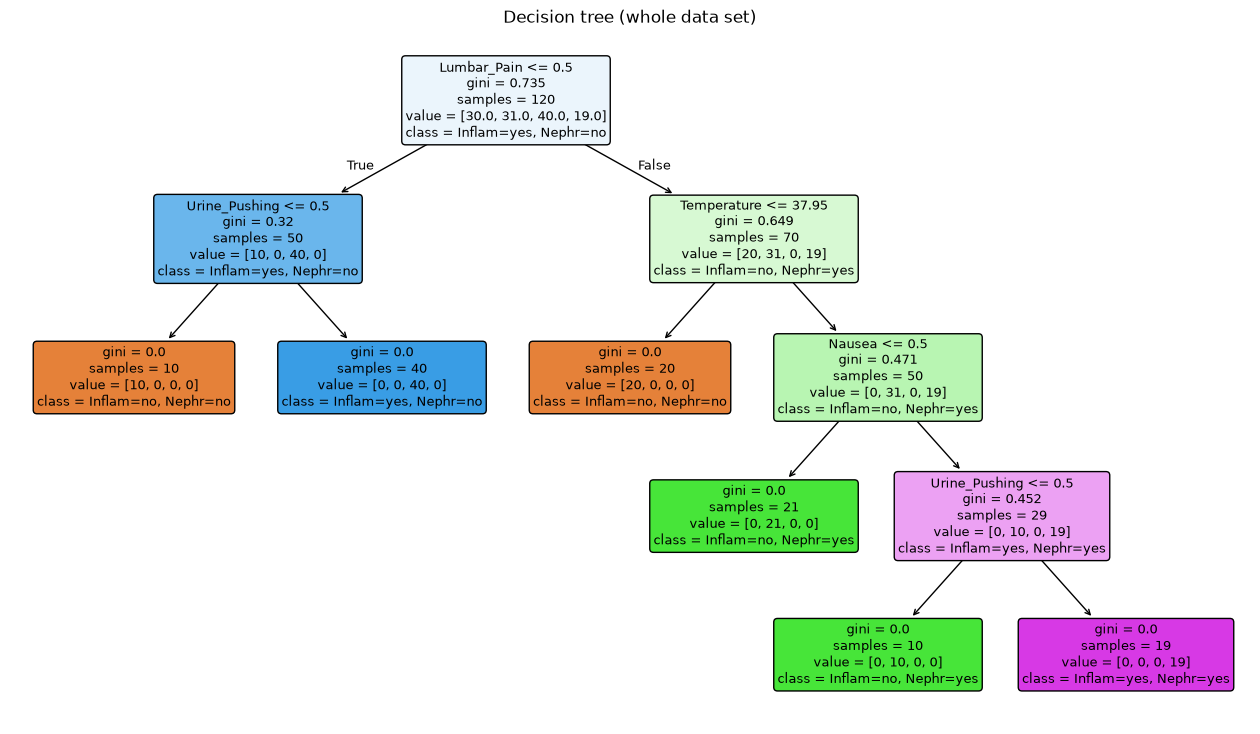

leaves: 6  depth: 4  training accuracy: 1.0


In [3]:
X1 = diag[q1_cols[:6]]
y1 = diag['Inflammation'].astype(str) + diag['Nephritis'].astype(str)

class_names = {'00': 'Inflam=no, Nephr=no', '01': 'Inflam=no, Nephr=yes',
               '10': 'Inflam=yes, Nephr=no', '11': 'Inflam=yes, Nephr=yes'}
print(y1.map(class_names).value_counts())

tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X1, y1)

plt.figure(figsize=(16, 9))
plot_tree(tree_full, feature_names=list(X1.columns),
          class_names=[class_names[c] for c in tree_full.classes_],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision tree (whole data set)')
plt.show()

print('leaves:', tree_full.get_n_leaves(), ' depth:', tree_full.get_depth(),
      ' training accuracy:', tree_full.score(X1, y1))

### (c) IF-THEN rules

The function below walks from the root to every leaf and writes the path as a rule (based on the idea in the KDnuggets
article given in the homework). Since all features except Temperature are yes/no, I print `Nausea = no` instead of `Nausea <= 0.5`.

In [4]:
def get_rules(model, feature_names, binary_features):
    t = model.tree_
    rules = []

    def cond(name, thr, left):
        if name in binary_features:
            return f"{name} = {'no' if left else 'yes'}"
        return f"{name} {'<=' if left else '>'} {thr:.2f}"

    def recurse(node, path):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_names[t.feature[node]]
            thr = t.threshold[node]
            recurse(t.children_left[node], path + [cond(name, thr, True)])
            recurse(t.children_right[node], path + [cond(name, thr, False)])
        else:
            counts = t.value[node][0]
            label = model.classes_[np.argmax(counts)]
            n = t.n_node_samples[node]
            rules.append((path, label, n))

    recurse(0, [])
    return rules


def print_rules(rules):
    for i, (path, label, n) in enumerate(rules, 1):
        print(f"Rule {i}: IF {' AND '.join(path)} THEN {class_names[label]}   ({n} samples)")


binary_feats = q1_cols[1:6]
print_rules(get_rules(tree_full, list(X1.columns), binary_feats))

Rule 1: IF Lumbar_Pain = no AND Urine_Pushing = no THEN Inflam=no, Nephr=no   (10 samples)
Rule 2: IF Lumbar_Pain = no AND Urine_Pushing = yes THEN Inflam=yes, Nephr=no   (40 samples)
Rule 3: IF Lumbar_Pain = yes AND Temperature <= 37.95 THEN Inflam=no, Nephr=no   (20 samples)
Rule 4: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = no THEN Inflam=no, Nephr=yes   (21 samples)
Rule 5: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = no THEN Inflam=no, Nephr=yes   (10 samples)
Rule 6: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = yes THEN Inflam=yes, Nephr=yes   (19 samples)


The full tree gives 6 rules, one for each leaf, and it classifies all 120 training samples correctly.
Lumbar pain is the first split: without lumbar pain, Nephritis never appears and Inflammation depends only on urine pushing.
With lumbar pain, a temperature above 37.95 is what separates Nephritis.

### (d) Cost-complexity pruning

I take the sequence of `ccp_alpha` values from the pruning path and use 5-fold (stratified) cross-validation
to compare the trees.

In [5]:
path = tree_full.cost_complexity_pruning_path(X1, y1)
alphas_q1 = path.ccp_alphas
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for a in alphas_q1:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X1, y1)
    scores = cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a), X1, y1, cv=cv5)
    rows.append([a, clf.get_n_leaves(), clf.get_depth(), clf.score(X1, y1), scores.mean(), scores.std()])

prune_df = pd.DataFrame(rows, columns=['ccp_alpha', 'leaves', 'depth', 'train_acc', 'cv_acc', 'cv_std'])
prune_df.round(4)

,ccp_alpha,leaves,depth,train_acc,cv_acc,cv_std
0,0.0000,6,4,1.0000,0.9917,0.0167
1,0.0982,4,2,0.8417,0.8583,0.0500
2,0.1333,3,2,0.7583,0.7583,0.0667
3,0.1820,2,1,0.5917,0.6667,0.0589
4,0.2229,1,0,0.3333,0.4833,0.1225


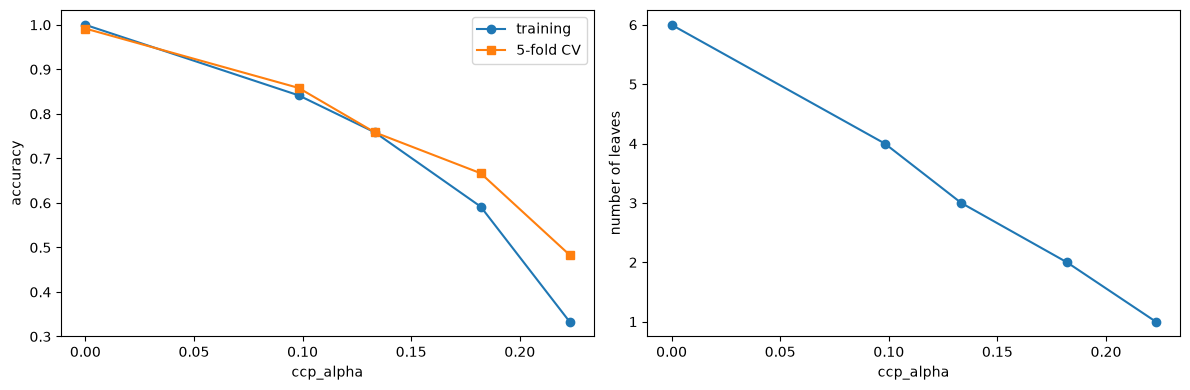

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(prune_df['ccp_alpha'], prune_df['train_acc'], 'o-', label='training')
ax[0].plot(prune_df['ccp_alpha'], prune_df['cv_acc'], 's-', label='5-fold CV')
ax[0].set_xlabel('ccp_alpha')
ax[0].set_ylabel('accuracy')
ax[0].legend()
ax[1].plot(prune_df['ccp_alpha'], prune_df['leaves'], 'o-')
ax[1].set_xlabel('ccp_alpha')
ax[1].set_ylabel('number of leaves')
plt.tight_layout()
plt.show()

CV accuracy is highest for the smallest `ccp_alpha` (the 6-leaf tree), and it drops a lot as soon as we prune more
(6 → 4 leaves). Using the one-standard-error rule (pick the largest alpha whose CV accuracy is within one SE of the best)
gives the same tree, so the selected tree is still the 6-leaf tree.

In [7]:
best = prune_df['cv_acc'].idxmax()
se = prune_df.loc[best, 'cv_std'] / np.sqrt(5)
ok = prune_df[prune_df['cv_acc'] >= prune_df.loc[best, 'cv_acc'] - se]
alpha_1se = ok['ccp_alpha'].max()
print('best alpha:', prune_df.loc[best, 'ccp_alpha'], ' alpha with 1-SE rule:', alpha_1se)

tree_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha_1se).fit(X1, y1)
print('leaves:', tree_pruned.get_n_leaves(), ' depth:', tree_pruned.get_depth())

best alpha: 0.0  alpha with 1-SE rule: 0.0
leaves: 6  depth: 4


For comparison, this is the next smaller tree in the path (4 leaves):

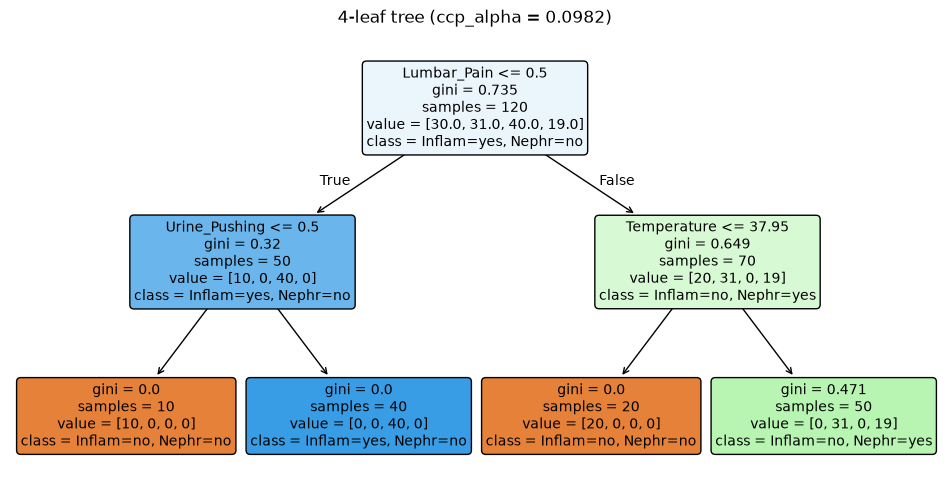

Rule 1: IF Lumbar_Pain = no AND Urine_Pushing = no THEN Inflam=no, Nephr=no   (10 samples)
Rule 2: IF Lumbar_Pain = no AND Urine_Pushing = yes THEN Inflam=yes, Nephr=no   (40 samples)
Rule 3: IF Lumbar_Pain = yes AND Temperature <= 37.95 THEN Inflam=no, Nephr=no   (20 samples)
Rule 4: IF Lumbar_Pain = yes AND Temperature > 37.95 THEN Inflam=no, Nephr=yes   (50 samples)

classes predicted by the 4-leaf tree: ['00', '01', '10']


In [8]:
alpha_4 = prune_df.loc[prune_df['leaves'] == 4, 'ccp_alpha'].iloc[0]
tree_4 = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha_4).fit(X1, y1)

plt.figure(figsize=(12, 6))
plot_tree(tree_4, feature_names=list(X1.columns),
          class_names=[class_names[c] for c in tree_4.classes_],
          filled=True, rounded=True, fontsize=10)
plt.title(f'4-leaf tree (ccp_alpha = {alpha_4:.4f})')
plt.show()

print_rules(get_rules(tree_4, list(X1.columns), binary_feats))
print('\nclasses predicted by the 4-leaf tree:', sorted(set(tree_4.predict(X1))))

The 4-leaf tree is shorter, but it **never predicts the "both diseases" class** (Inflam=yes, Nephr=yes), so all 19 patients
who have both are misclassified, and the CV accuracy falls from about 0.99 to about 0.86. For a medical diagnosis this is not
acceptable, so I keep the CV-selected tree.

The selected tree can still be made easier to read. Rules 4 and 5 of the full tree have the same conclusion, so they can be merged:
"Nausea = no" OR "Nausea = yes AND Urine_Pushing = no" is the same as NOT (Nausea = yes AND Urine_Pushing = yes).
The final rule set is:

1. IF Lumbar_Pain = no AND Urine_Pushing = no THEN no Inflammation, no Nephritis
2. IF Lumbar_Pain = no AND Urine_Pushing = yes THEN Inflammation only
3. IF Lumbar_Pain = yes AND Temperature ≤ 37.95 THEN no Inflammation, no Nephritis
4. IF Lumbar_Pain = yes AND Temperature > 37.95 AND NOT (Nausea = yes AND Urine_Pushing = yes) THEN Nephritis only
5. IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = yes THEN both

Five short rules using only 4 of the 6 features (Micturition pains and Burning of urethra are never used).

## 2. The LASSO and Boosting for Regression

### (a) Load the data and split

Column names are read from `communities.names` so the selected variables can be reported by name.

In [9]:
with open('communities.names') as f:
    crime_cols = [line.split()[1] for line in f if line.startswith('@attribute')]

crime = pd.read_csv('communities.data', header=None, names=crime_cols, na_values='?')
print(crime.shape)

train = crime.iloc[:1495]
test = crime.iloc[1495:]
print('train:', train.shape, ' test:', test.shape)

(1994, 128)
train: (1495, 128)  test: (499, 128)


### (b) Missing values

According to the data description, the first five attributes (state, county, community, communityname, fold) are not predictive,
so they are removed. The target is `ViolentCrimesPerPop`.

In [10]:
non_pred = ['state', 'county', 'community', 'communityname', 'fold']
target = 'ViolentCrimesPerPop'

X_train = train.drop(columns=non_pred + [target])
X_test = test.drop(columns=non_pred + [target])
y_train = train[target]
y_test = test[target]

miss = X_train.isna().mean()
print(miss[miss > 0].sort_values(ascending=False).round(3))

LemasSwornFT            0.840
LemasSwFTPerPop         0.840
LemasSwFTFieldOps       0.840
LemasTotalReq           0.840
LemasSwFTFieldPerPop    0.840
LemasTotReqPerPop       0.840
PolicReqPerOffic        0.840
OfficAssgnDrugUnits     0.840
PolicPerPop             0.840
RacialMatchCommPol      0.840
PctPolicWhite           0.840
PctPolicBlack           0.840
PctPolicHisp            0.840
PctPolicAsian           0.840
PctPolicMinor           0.840
PolicOperBudg           0.840
NumKindsDrugsSeiz       0.840
PolicAveOTWorked        0.840
PolicCars               0.840
LemasGangUnitDeploy     0.840
LemasPctPolicOnPatr     0.840
PolicBudgPerPop         0.840
OtherPerCap             0.001
dtype: float64


Only a few columns have missing values. One column (`OtherPerCap`) has a single missing value; the other ones are the
police-related variables (LEMAS survey), which are missing for most communities. I used mean imputation, fitted on the training
set only, and applied the same means to the test set.

In [11]:
imp = SimpleImputer(strategy='mean')
X_train = pd.DataFrame(imp.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imp.transform(X_test), columns=X_test.columns, index=X_test.index)
print(X_train.shape, X_test.shape, X_train.isna().sum().sum(), X_test.isna().sum().sum())

(1495, 122) (499, 122) 0 0


### (c) Correlation matrix

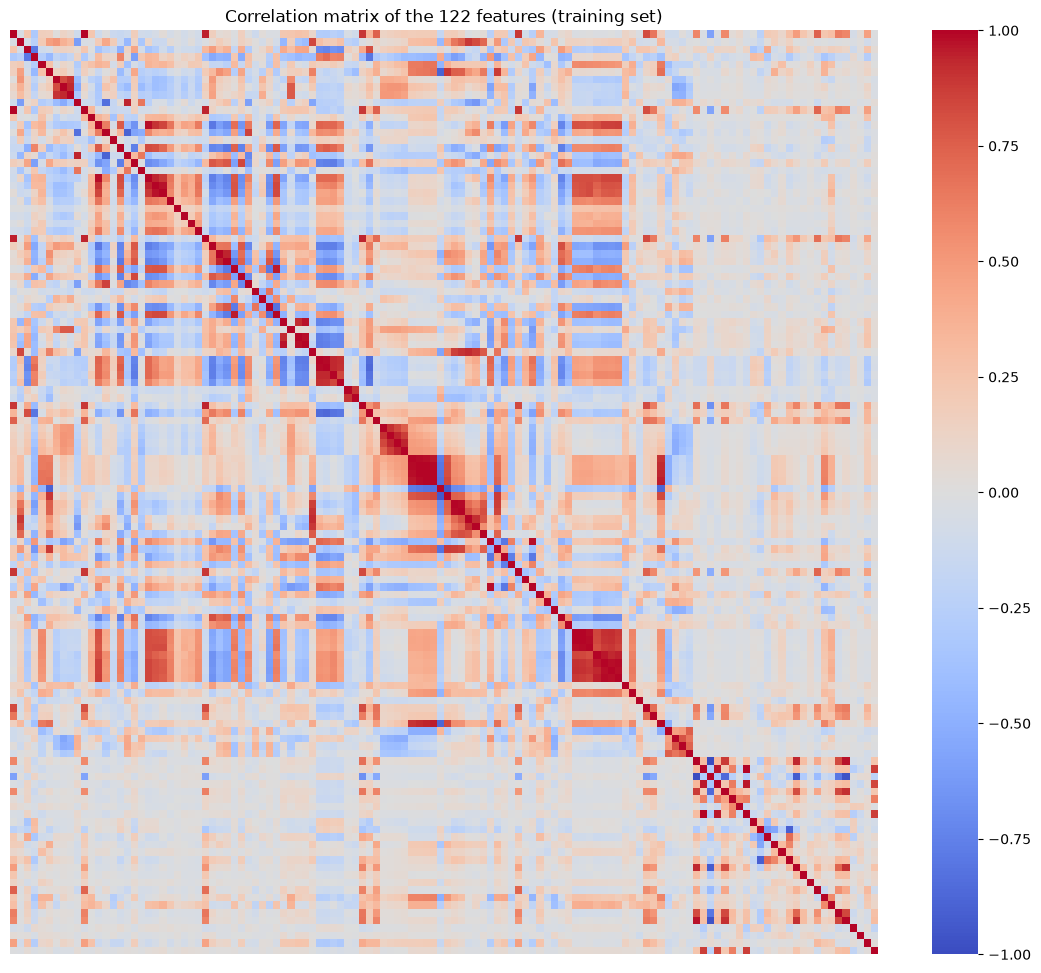

LemasSwFTPerPop  PolicPerPop          1.000000
PctRecImmig8     PctRecImmig10        0.995561
OwnOccLowQuart   OwnOccMedVal         0.994692
LemasSwornFT     LemasSwFTFieldOps    0.993998
population       numbUrban            0.993613
PctRecImmig5     PctRecImmig8         0.992735
OwnOccMedVal     OwnOccHiQuart        0.991559
PctRecentImmig   PctRecImmig5         0.989361
RentMedian       MedRent              0.988780
PctFam2Par       PctKids2Par          0.985623
dtype: float64

In [12]:
corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Correlation matrix of the 122 features (training set)')
plt.show()

# the most correlated pairs
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.abs().sort_values(ascending=False).head(10)

There are several large red blocks, so many features are strongly correlated with each other. Some pairs are almost
duplicates: `LemasSwFTPerPop` and `PolicPerPop` (r = 1.00), `population` and `numbUrban` (0.99), the `PctRecImmig*`
variables (0.99), `RentMedian` and `MedRent` (0.99). With this much collinearity the OLS coefficients will be unstable,
which is a reason to try ridge, LASSO and PCR.
The police variables in the bottom-right corner look weakly correlated with everything else, partly because 84% of their
values were filled with the same mean.

### (d) Coefficient of variation

CV = s / m for each feature (computed on the training set).

In [13]:
cv_feat = (X_train.std() / X_train.mean()).sort_values(ascending=False)
cv_feat.round(4)

NumStreet              4.2929
NumInShelters          3.4710
NumIlleg               3.0590
NumImmig               2.9266
LemasPctOfficDrugUn    2.5529
                        ...  
NumKindsDrugsSeiz      0.1444
RacialMatchCommPol     0.1349
PctPolicWhite          0.1228
LemasPctPolicOnPatr    0.1157
LemasSwFTFieldOps      0.0643
Length: 122, dtype: float64

### (e) Features with the highest CV

$\lfloor\sqrt{128}\rfloor = 11$, so I take the top 11 features.

In [14]:
k = int(np.floor(np.sqrt(128)))
top = cv_feat.index[:k].tolist()
print(k, top)

11 ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


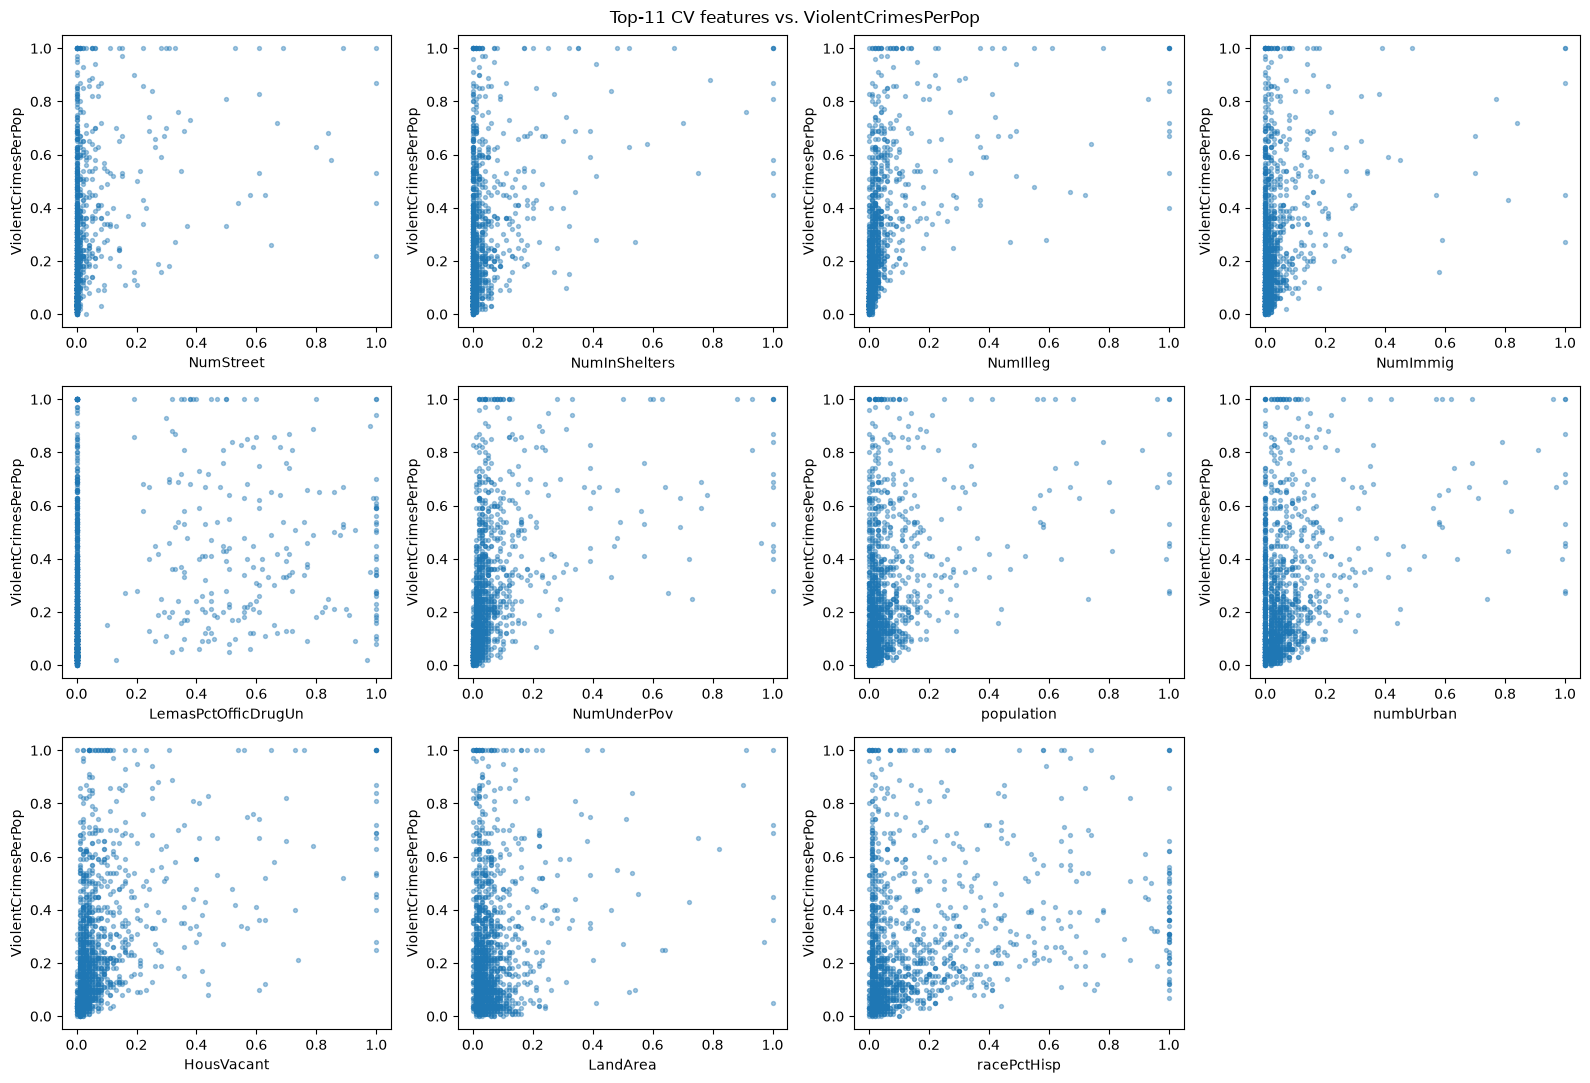

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, top):
    ax.scatter(X_train[f], y_train, s=8, alpha=0.4)
    ax.set_xlabel(f)
    ax.set_ylabel(target)
axes.flat[-1].axis('off')
plt.suptitle('Top-11 CV features vs. ViolentCrimesPerPop')
plt.tight_layout()
plt.show()

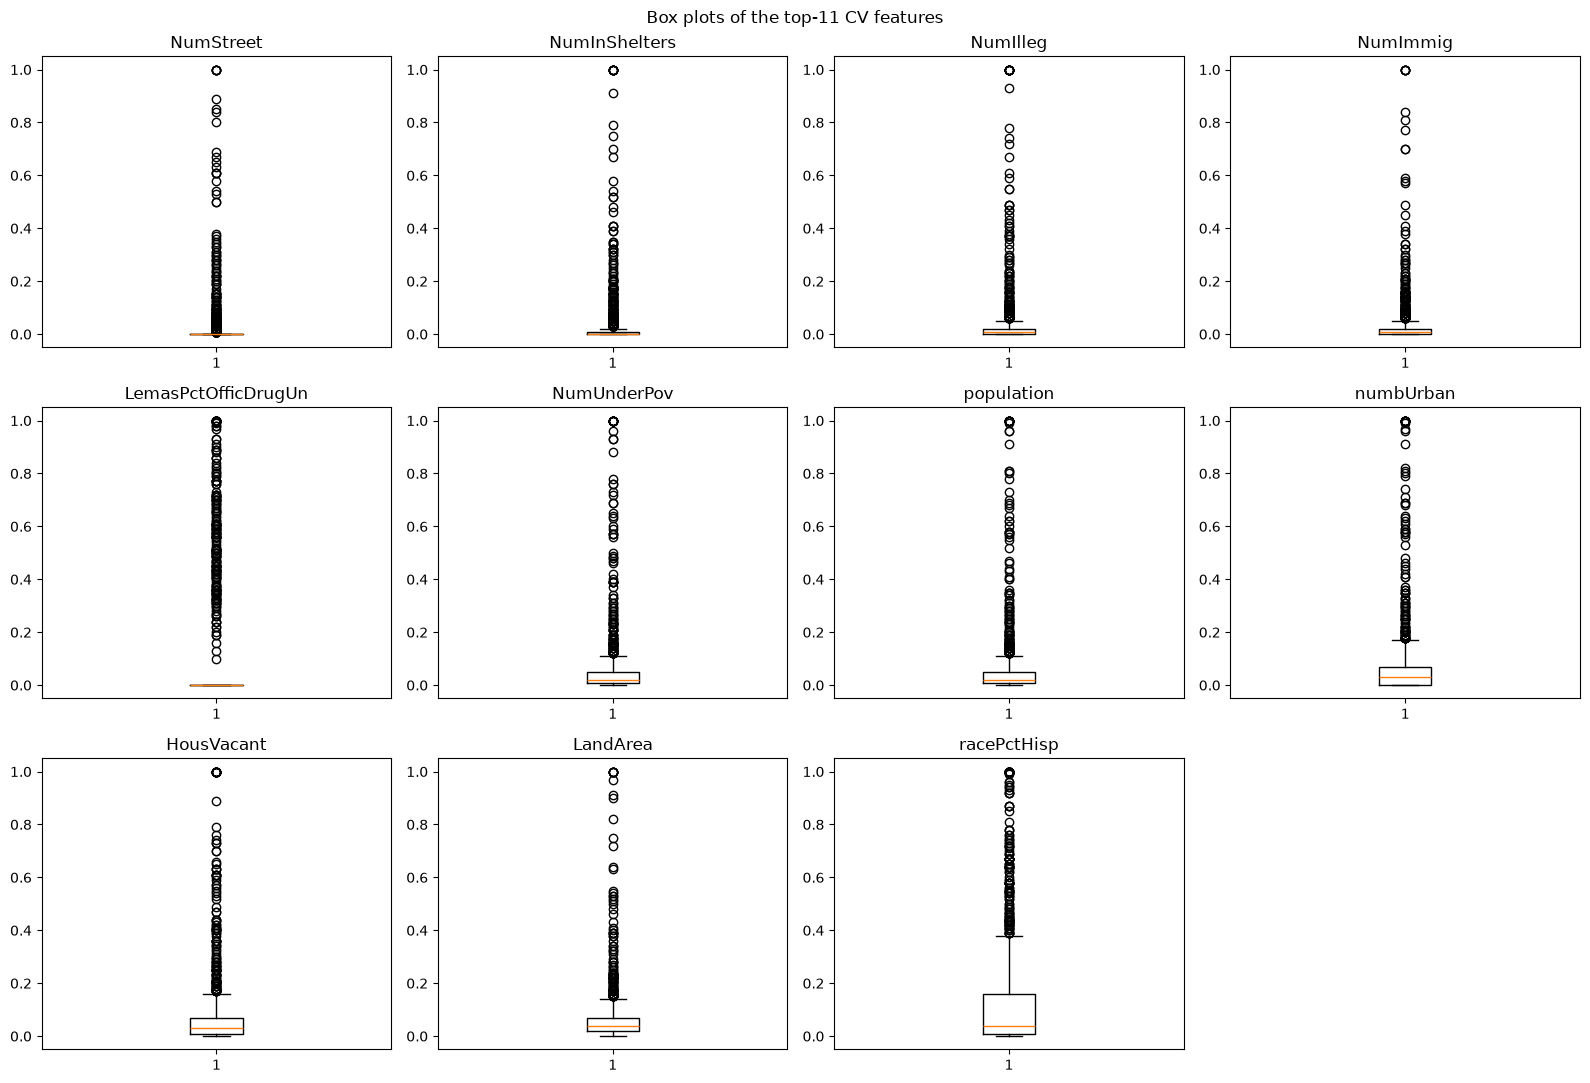

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, top):
    ax.boxplot(X_train[f])
    ax.set_title(f)
axes.flat[-1].axis('off')
plt.suptitle('Box plots of the top-11 CV features')
plt.tight_layout()
plt.show()

Most of the 11 features are counts or sizes (`NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `population`, ...).
The box plots show they are very right-skewed: the box is squeezed near 0 and there is a long tail of outliers up to 1.
That is why their CV is high (small mean, relatively large s). `LemasPctOfficDrugUn` is a special case, since it is 0 for most
communities, and its high CV mostly comes from missing data and zeros.

In the scatter plots, some features (`NumIlleg`, `NumUnderPov`, `HousVacant`) show a weak upward trend with violent crime,
but the points are spread over the whole range of the target.

**Can we conclude significance from these plots? No.** A scatter plot only shows the marginal relationship with the target.
It does not account for the other features (for example `population` and `numbUrban` are almost the same variable), and it gives
no standard error or p-value. A high CV also only means the feature varies a lot relative to its mean; it says nothing about
how related it is to the response. We would need to fit a model and test the coefficients (t-test / F-test) to talk about significance.

### (f) Linear regression (least squares)

In [17]:
ols = LinearRegression().fit(X_train, y_train)
mse_ols = mean_squared_error(y_test, ols.predict(X_test))
print(f'OLS test MSE: {mse_ols:.5f}')

OLS test MSE: 0.01814


### (g) Ridge regression

In [18]:
lam_grid = np.logspace(-4, 4, 100)
ridge_cv = GridSearchCV(Ridge(), {'alpha': lam_grid}, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train, y_train)

mse_ridge = mean_squared_error(y_test, ridge_cv.predict(X_test))
print(f"best lambda: {ridge_cv.best_params_['alpha']:.4f}")
print(f'CV MSE: {-ridge_cv.best_score_:.5f}')
print(f'Ridge test MSE: {mse_ridge:.5f}')

best lambda: 2.3101
CV MSE: 0.01906
Ridge test MSE: 0.01760


### (h) LASSO

In [19]:
lasso = LassoCV(alphas=100, cv=5, max_iter=100000, random_state=42)
lasso.fit(X_train, y_train)
mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))

coef = pd.Series(lasso.coef_, index=X_train.columns)
sel = coef[coef != 0]
print(f'best lambda: {lasso.alpha_:.6f}')
print(f'LASSO test MSE: {mse_lasso:.5f}')
print(f'{len(sel)} of {len(coef)} variables selected:')
print(sel.sort_values(key=abs, ascending=False).round(4).to_string())

best lambda: 0.000116
LASSO test MSE: 0.01776
75 of 122 variables selected:
racepctblack             0.2720
agePct12t29             -0.2654
PctPersDenseHous         0.2190
PctKids2Par             -0.1966
NumStreet                0.1664
MedRent                  0.1612
RentLowQ                -0.1589
PctPopUnderPov          -0.1412
PctEmploy                0.1374
MalePctNevMarr           0.1332
PctWorkMom              -0.1295
HousVacant               0.1242
MalePctDivorce           0.1181
pctWRetire              -0.1084
pctWInvInc              -0.0985
PctIlleg                 0.0985
PolicReqPerOffic         0.0906
MedRentPctHousInc        0.0901
pctWWage                -0.0848
FemalePctDiv            -0.0786
MedOwnCostPctIncNoMtg   -0.0778
PctVacantBoarded         0.0734
PctNotSpeakEnglWell     -0.0707
NumImmig                -0.0704
LemasSwFTFieldPerPop     0.0703
agePct12t21              0.0667
PctLargHouseOccup       -0.0649
PctHousOccup            -0.0605
PctVacMore6Mos          -0.0

Repeat with standardized features (The features are standardized before fitting LASSO with cross-validation.):

In [20]:
lasso_std = Pipeline([('scale', StandardScaler()),
                      ('lasso', LassoCV(alphas=100, cv=5, max_iter=100000, random_state=42))])
lasso_std.fit(X_train, y_train)
mse_lasso_std = mean_squared_error(y_test, lasso_std.predict(X_test))

coef_std = pd.Series(lasso_std.named_steps['lasso'].coef_, index=X_train.columns)
sel_std = coef_std[coef_std != 0]
print(f"best lambda: {lasso_std.named_steps['lasso'].alpha_:.6f}")
print(f'LASSO (standardized) test MSE: {mse_lasso_std:.5f}')
print(f'{len(sel_std)} of {len(coef_std)} variables selected:')
print(sel_std.sort_values(key=abs, ascending=False).round(4).to_string())

best lambda: 0.000763
LASSO (standardized) test MSE: 0.01781
73 of 122 variables selected:
racepctblack             0.0682
PctPersDenseHous         0.0406
PctKids2Par             -0.0398
agePct12t29             -0.0383
RentLowQ                -0.0277
PctPopUnderPov          -0.0267
MedRent                  0.0264
PctIlleg                 0.0247
PctWorkMom              -0.0214
PctEmploy                0.0212
pctWInvInc              -0.0208
MalePctNevMarr           0.0207
MalePctDivorce           0.0190
NumStreet                0.0182
HousVacant               0.0172
pctWRetire              -0.0172
pctUrban                 0.0166
MedRentPctHousInc        0.0151
PctVacantBoarded         0.0146
MedOwnCostPctIncNoMtg   -0.0141
pctWWage                -0.0121
PctHousOccup            -0.0117
agePct12t21              0.0104
PctVacMore6Mos          -0.0102
FemalePctDiv            -0.0101
PctHousLess3BR           0.0094
PctPersOwnOccup         -0.0094
PolicReqPerOffic         0.0092
pctWSocSec   

In [21]:
print('selected only without standardization:', sorted(set(sel.index) - set(sel_std.index)))
print('selected only with standardization:   ', sorted(set(sel_std.index) - set(sel.index)))

selected only without standardization: ['LemasPctOfficDrugUn', 'MedNumBR', 'OwnOccLowQuart', 'PctBornSameState', 'PctOccupManu', 'PolicBudgPerPop']
selected only with standardization:    ['PctImmigRec5', 'PctPolicHisp', 'PctPolicWhite', 'PolicCars']


| | λ (CV) | test MSE | # selected |
|---|---|---|---|
| LASSO, original features | 0.000116 | 0.01776 | 75 |
| LASSO, standardized features | 0.000763 | 0.01781 | 73 |

The two versions are almost the same: the test MSE differs by only 0.00005, and 69 variables are selected by both.
This makes sense because, as the homework says, the features are already normalized to [0, 1], so standardizing does not
change their scales very much. λ is different only because the coefficients are on a different scale.
In both models the largest coefficients belong to `racepctblack`, `agePct12t29`, `PctPersDenseHous`, `PctKids2Par`,
`RentLowQ`, `MedRent` and `PctPopUnderPov`.

The chosen λ is small, so LASSO still keeps more than half of the 122 variables, and its test error is slightly worse than ridge.

### (i) PCR

In [22]:
pcr = Pipeline([('scale', StandardScaler()), ('pca', PCA()), ('lr', LinearRegression())])
pcr_cv = GridSearchCV(pcr, {'pca__n_components': range(1, X_train.shape[1] + 1)},
                      cv=5, scoring='neg_mean_squared_error')
pcr_cv.fit(X_train, y_train)

mse_pcr = mean_squared_error(y_test, pcr_cv.predict(X_test))
print('best M:', pcr_cv.best_params_['pca__n_components'])
print(f'CV MSE: {-pcr_cv.best_score_:.5f}')
print(f'PCR test MSE: {mse_pcr:.5f}')

best M: 95
CV MSE: 0.01935
PCR test MSE: 0.01839


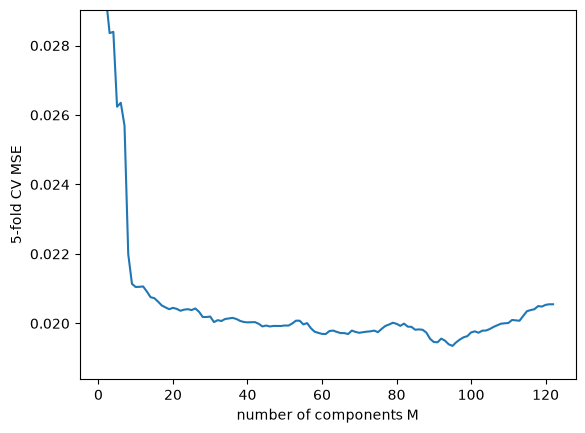

In [23]:
cv_curve = -pcr_cv.cv_results_['mean_test_score']
plt.plot(range(1, len(cv_curve) + 1), cv_curve)
plt.xlabel('number of components M')
plt.ylabel('5-fold CV MSE')
plt.ylim(cv_curve.min() * 0.95, cv_curve.min() * 1.5)
plt.show()

The CV error drops quickly over the first ~10 components and is then almost flat (around 0.020) from about 20 to 100 components.
The minimum is at M = 95, but because the curve is so flat, a much smaller M (20–30) would give nearly the same CV error.
The PCR test MSE (0.01839) is a bit worse than plain OLS. PCA chooses directions with the largest variance in X, and these
are not necessarily the directions that predict crime.

### (j) Boosting with XGBoost

XGBoost's `reg_alpha` is the L1 penalty on the leaf weights of the boosted regression trees. This is not exactly a model tree
with an L1-penalized linear regression in each node, but it is the L1-penalized gradient boosting that XGBoost provides,
and α is chosen by 5-fold CV. The other settings (200 trees, depth 3, learning rate 0.05) were kept fixed so that only α is tuned.

In [24]:
xgb = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
xgb_cv = GridSearchCV(xgb, {'reg_alpha': np.logspace(-4, 2, 15)}, cv=5,
                      scoring='neg_mean_squared_error')
xgb_cv.fit(X_train, y_train)

mse_xgb = mean_squared_error(y_test, xgb_cv.predict(X_test))
print(f"best alpha: {xgb_cv.best_params_['reg_alpha']:.4f}")
print(f'CV MSE: {-xgb_cv.best_score_:.5f}')
print(f'XGBoost test MSE: {mse_xgb:.5f}')

best alpha: 0.7197
CV MSE: 0.02008
XGBoost test MSE: 0.01638


### Summary of test errors

In [25]:
summary = pd.Series({'OLS': mse_ols, 'Ridge': mse_ridge, 'LASSO': mse_lasso,
                     'LASSO (standardized)': mse_lasso_std, 'PCR': mse_pcr, 'XGBoost': mse_xgb},
                    name='test MSE').sort_values()
summary.round(5)

XGBoost                 0.01638
Ridge                   0.01760
LASSO                   0.01776
LASSO (standardized)    0.01781
OLS                     0.01814
PCR                     0.01839
Name: test MSE, dtype: float64

- The linear models are all close (0.0176–0.0184). Ridge and LASSO are a little better than OLS, which is expected with
  so many highly correlated features. PCR is the worst of the linear models.
- XGBoost has the lowest test MSE (0.01638), about 7% lower than ridge. Boosted trees can capture nonlinear effects and interactions.
- However, the 5-fold CV MSE of XGBoost on the training set was actually a bit higher than ridge's (see the outputs above),
  so part of its advantage on the test set may come from this particular train/test split.